In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
from scipy.ndimage import maximum_filter, label

In [2]:
#Function Definitions
def partial_x_2d(f,dx):
    """Compute ∂f/∂x using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dx = np.zeros_like(f)
    
    # Central difference in x-direction (axis=0)
    df_dx[1:Nx-1, :] = (f[2:Nx, :] - f[0:Nx-2, :]) / (2 * dx)
    
    # Periodic boundaries (x-direction)
    df_dx[0, :] = (f[1, :] - f[-1, :]) / (2 * dx)
    df_dx[-1, :] = (f[0, :] - f[-2, :]) / (2 * dx)
    
    return df_dx

def partial_y_2d(f,dy):
    """Compute ∂f/∂y using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dy = np.zeros_like(f)
    
    # Central difference in y-direction (axis=1)
    df_dy[:, 1:Ny-1] = (f[:, 2:Ny] - f[:, 0:Ny-2]) / (2 * dy)
    
    # Periodic boundaries (y-direction)
    df_dy[:, 0] = (f[:, 1] - f[:, -1]) / (2 * dy)
    df_dy[:, -1] = (f[:, 0] - f[:, -2]) / (2 * dy)
    
    return df_dy

def partial_x_fft(f, dx):
    """
    Calculate ∂f/∂x using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dx (float): Grid spacing in the x-direction.

    Returns:
        df_dx (2D np.array): Partial derivative ∂f/∂x.
    """
    nx, ny = f.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi  # Wavenumbers in x
    kx = kx[:, np.newaxis]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dx_hat = 1j * kx * f_hat
    df_dx = np.fft.ifft2(df_dx_hat).real

    return np.array(df_dx)

def partial_y_fft(f, dy):
    """
    Calculate ∂f/∂y using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dy (float): Grid spacing in the y-direction.

    Returns:
        df_dy (2D np.array): Partial derivative ∂f/∂y.
    """
    nx, ny = f.shape
    ky = np.fft.fftfreq(ny, d=dy) * 2 * np.pi  # Wavenumbers in y
    ky = ky[np.newaxis, :]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dy_hat = 1j * ky * f_hat
    df_dy = np.fft.ifft2(df_dy_hat).real

    return df_dy

def index_of_just_smaller(arr, value):
    arr = np.asarray(arr)
    mask = arr < value
    if not np.any(mask):
        return None  # No smaller value exists
    return np.argmax(np.where(mask, arr, -np.inf))

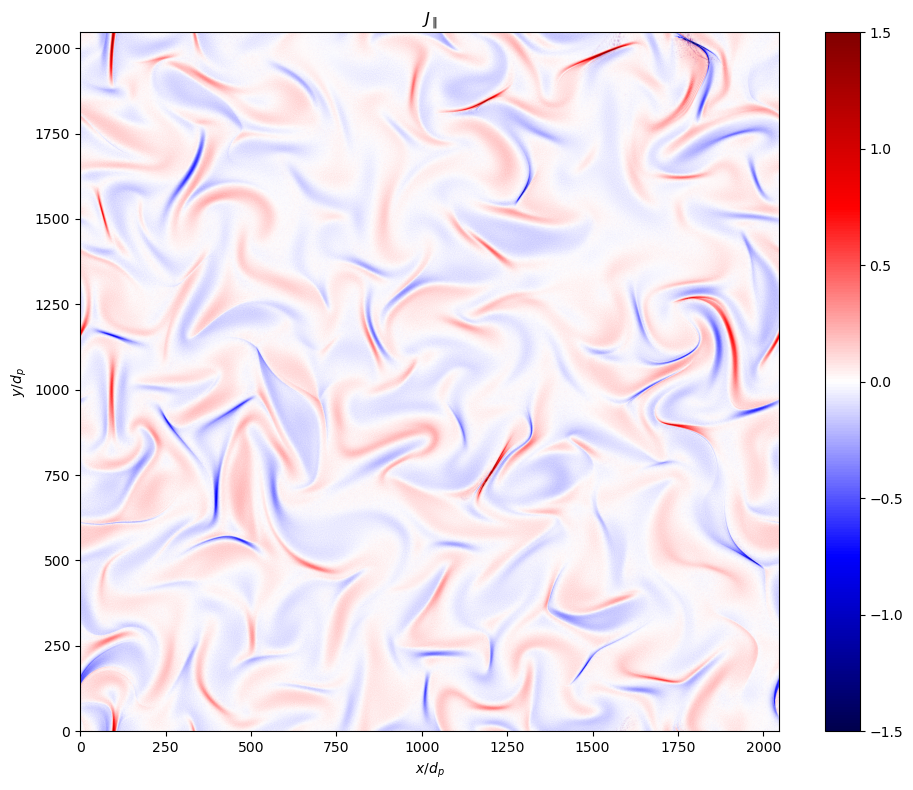

In [3]:
#Lets Plot J_Parallel

File_Bx = '/DATA/DEVESH/ApJ2015/Bx_ApJ_t42.h5'
File_By = '/DATA/DEVESH/ApJ2015/By_ApJ_t42.h5'


with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

#Compute J_parallel using Fourier Transform
J_par_FT = partial_x_fft(data_By,0.125)-partial_y_fft(data_Bx,0.125)

# 2. Plot the 2D matrix
plt.figure(figsize=(10, 8))

# Basic image plot
img = plt.imshow(J_par_FT[:,:].T, cmap='seismic', vmin=-1.5, vmax=1.5, origin='lower')  # You can change the colormap (e.g., 'hot', 'plasma', 'gray')

# Add colorbar
plt.colorbar(img)

# Add titles and labels
plt.title(r'$J_\parallel$')
plt.xlabel(r'$x/d_{p}$')
plt.ylabel(r'$y/d_{p}$')

# Show the plot
plt.tight_layout()
plt.savefig('CS.png',dpi=300)
plt.show()

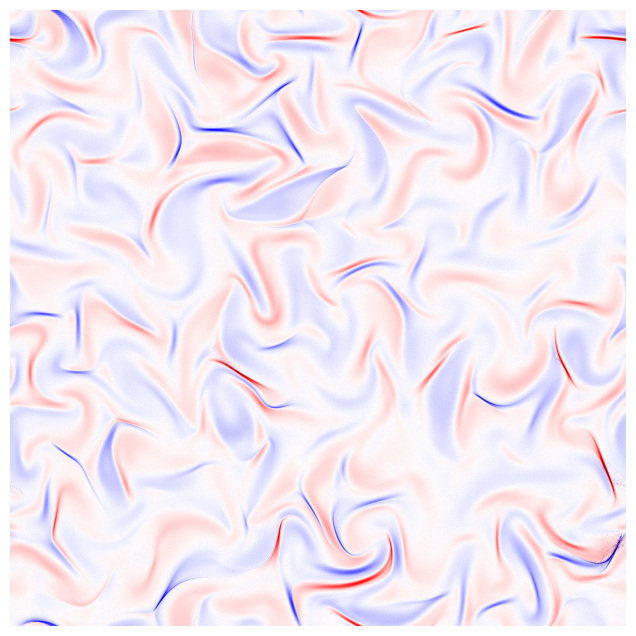

In [8]:
# 2. Plot the 2D matrix
plt.figure(figsize=(10, 8))

# Basic image plot (no axis labels, no colorbar)
plt.imshow(J_par_FT, cmap='seismic', vmin=-1.5, vmax=1.5)

# Remove axes, ticks, and labels
plt.axis('off')

# Save only the image, no border
plt.savefig('CS.png', bbox_inches='tight', pad_inches=0,dpi=1000)

# Show the plot
plt.show()

In [9]:
#Lets Plot J_Parallel_rms

File_Bx = f'/DATA/DEVESH/ApJ2015/Bx_ApJ_t42.h5'
File_By = f'/DATA/DEVESH/ApJ2015/By_ApJ_t42.h5'
        
with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T
    
#Compute J_parallel using Fourier Transform
J_par_FT = partial_x_fft(data_By,0.125)-partial_y_fft(data_Bx,0.125)
    
J_rms = np.sqrt(np.mean(J_par_FT**2))

In [10]:
def local_maxima_mask(J_par_FT, J_thresh, n):
    # Take absolute value
    J_abs = np.abs(J_par_FT)
    
    # Apply threshold
    mask = J_abs > J_thresh
    
    # Compute local maximum in a (2n+1)x(2n+1) neighborhood
    local_max = maximum_filter(J_abs, size=(2*n+1), mode='wrap')
    
    # Keep only points that are equal to local maximum and above threshold
    maxima_mask = (J_abs == local_max) & mask
    
    return maxima_mask.astype(int)

# Example usage
J_thresh = J_rms
n = 50   # neighborhood radius
maxima_mask = local_maxima_mask(J_par_FT, J_thresh, n)

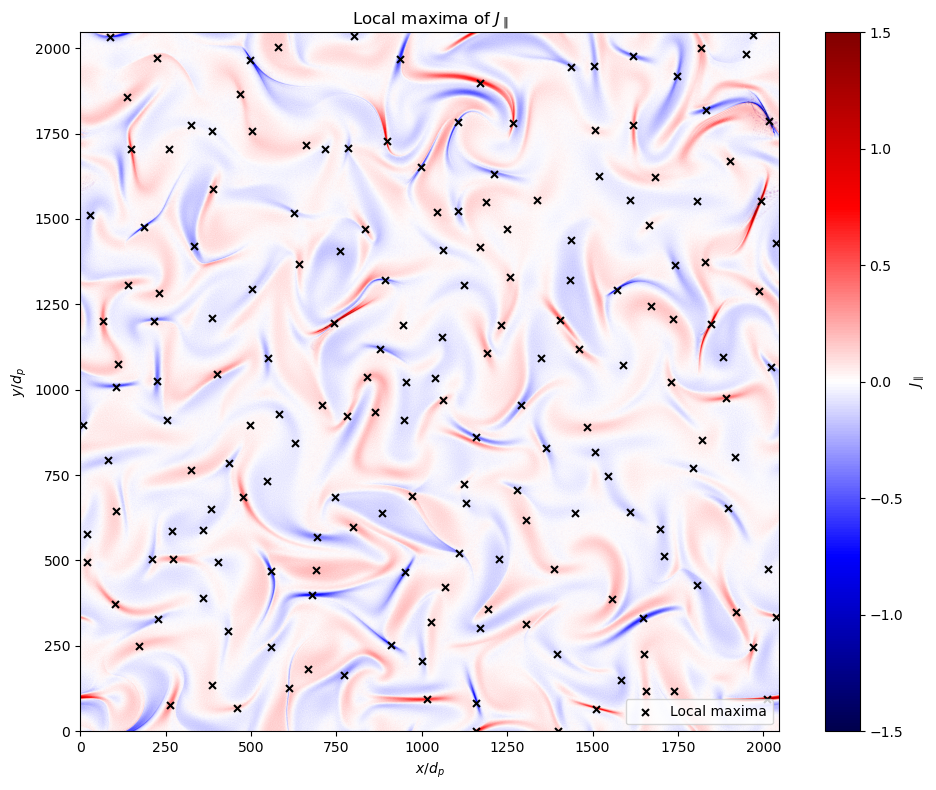

In [11]:
# Plot J_parallel with maxima overlay
plt.figure(figsize=(10, 8))
img = plt.imshow(J_par_FT, cmap='seismic', vmin=-1.5, vmax=1.5, origin='lower')
plt.colorbar(img, label=r'$J_\parallel$')

# Overlay local maxima
y_idx, x_idx = np.where(maxima_mask)
plt.scatter(x_idx, y_idx, marker='x', color='black', s=25, label='Local maxima')

plt.title(r'Local maxima of $J_\parallel$')
plt.xlabel(r'$x/d_{p}$')
plt.ylabel(r'$y/d_{p}$')
plt.legend()
plt.tight_layout()
plt.show()

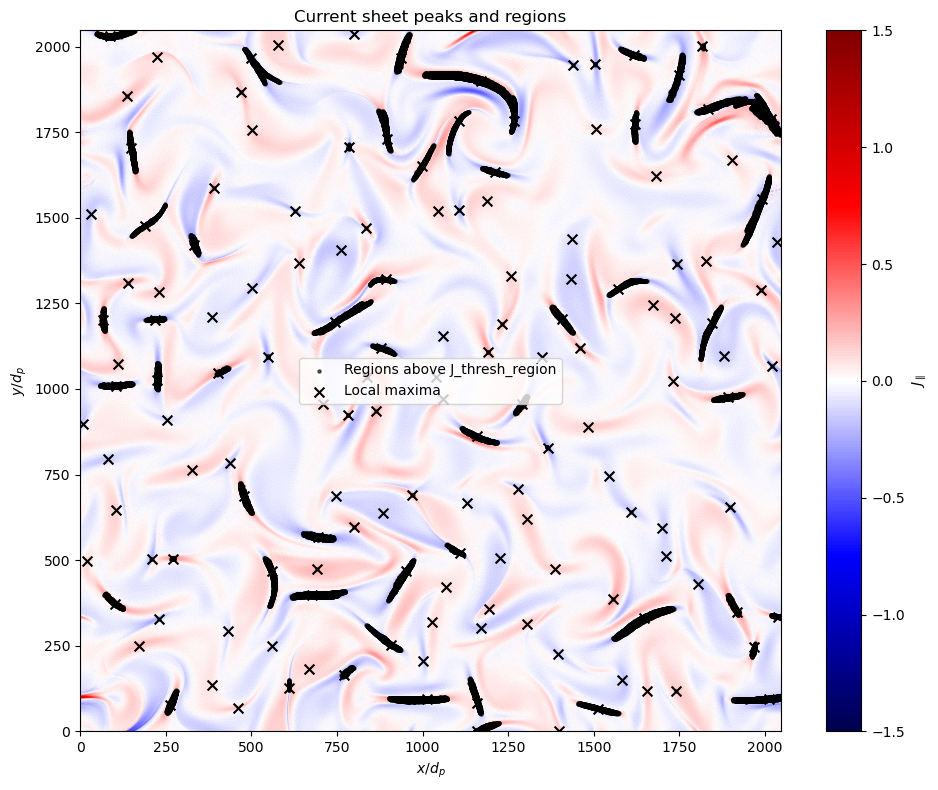

In [8]:
def local_maxima_mask(J_par_FT, J_thresh_peak, n):
    """Find local maxima above peak threshold in J_par_FT."""
    J_abs = np.abs(J_par_FT)
    mask = J_abs > J_thresh_peak
    local_max = maximum_filter(J_abs, size=(2*n+1), mode='wrap')
    maxima_mask = (J_abs == local_max) & mask
    return maxima_mask.astype(int)

def grow_regions(J_par_FT, maxima_mask, J_thresh_region):
    """Grow regions above region threshold connected to local maxima."""
    J_abs = np.abs(J_par_FT)

    # Mask of all points above region threshold
    above_thresh = (J_abs > J_thresh_region).astype(int)

    # Label connected regions
    labeled_regions, num_features = label(above_thresh, structure=np.ones((3,3)))

    # Keep only those regions that contain a local maximum
    keep_labels = np.unique(labeled_regions[maxima_mask.astype(bool)])
    keep_labels = keep_labels[keep_labels > 0]  # drop background=0

    region_mask = np.isin(labeled_regions, keep_labels).astype(int)

    return region_mask, labeled_regions


# ==== Example usage ====
J_thresh_peak = 2*J_rms     # threshold for detecting maxima
J_thresh_region = 0.08*np.max(np.abs(J_par_FT))   # threshold for growing regions
n = 50                   # neighborhood radius for non-max suppression

# Step 1: detect peaks
maxima_mask = local_maxima_mask(J_par_FT, J_thresh_peak, n)

# Step 2: grow regions around peaks
region_mask, labeled_regions = grow_regions(J_par_FT, maxima_mask, J_thresh_region)

# Step 3: plot results
plt.figure(figsize=(10, 8))
img = plt.imshow(J_par_FT, cmap='seismic', vmin=-1.5, vmax=1.5, origin='lower')
plt.colorbar(img, label=r'$J_\parallel$')

# Overlay region mask as small white dots
y_reg, x_reg = np.where(region_mask == 1)
plt.scatter(x_reg, y_reg, s=5, color='black', alpha=0.6, label='Regions above J_thresh_region')

# Overlay maxima as black X’s
y_peak, x_peak = np.where(maxima_mask == 1)
plt.scatter(x_peak, y_peak, marker='x', color='black', s=50, label='Local maxima')

plt.title(r'Current sheet peaks and regions')
plt.xlabel(r'$x/d_{p}$')
plt.ylabel(r'$y/d_{p}$')
plt.legend()
plt.tight_layout()
plt.show()

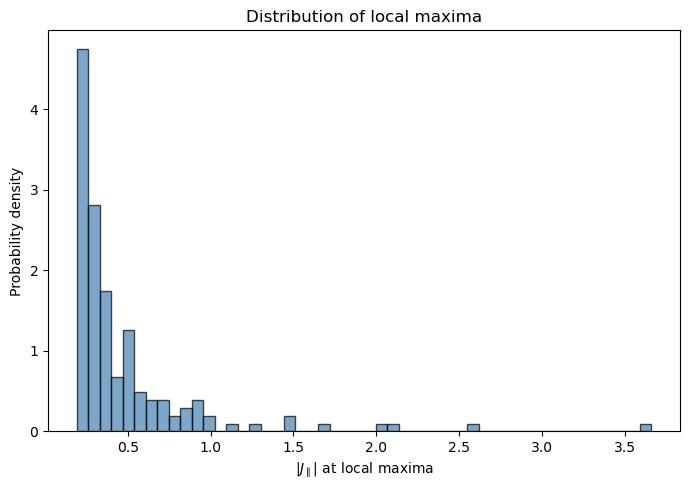

Number of local maxima found: 149


In [10]:
# Extract values of J at the detected maxima
J_maxima_values = np.abs(J_par_FT[maxima_mask.astype(bool)])

# ---- Histogram of maxima magnitudes ----
plt.figure(figsize=(7,5))
plt.hist(J_maxima_values, bins=50, density=True, alpha=0.7, color='steelblue', edgecolor='black')
plt.xlabel(r'$|J_\parallel|$ at local maxima')
plt.ylabel('Probability density')
plt.title('Distribution of local maxima')
plt.tight_layout()
plt.show()

# ---- Optional: return the values for further analysis ----
print(f"Number of local maxima found: {len(J_maxima_values)}")

In [11]:
def compute_hessian(J, x, y, dx=1.0, dy=1.0):
    """
    Compute 2D Hessian matrix at point (x,y) of array J using central differences.
    """
    d2f_dx2 = (J[y, (x+1)%J.shape[1]] - 2*J[y, x] + J[y, (x-1)%J.shape[1]]) / dx**2
    d2f_dy2 = (J[(y+1)%J.shape[0], x] - 2*J[y, x] + J[(y-1)%J.shape[0], x]) / dy**2
    d2f_dxdy = (
        J[(y+1)%J.shape[0], (x+1)%J.shape[1]] - J[(y+1)%J.shape[0], (x-1)%J.shape[1]]
        - J[(y-1)%J.shape[0], (x+1)%J.shape[1]] + J[(y-1)%J.shape[0], (x-1)%J.shape[1]]
    ) / (4*dx*dy)

    H = np.array([[d2f_dx2, d2f_dxdy],
                  [d2f_dxdy, d2f_dy2]])
    return H

def steepest_descent_direction(J, peaks, dx=1.0, dy=1.0):
    """
    For each peak, compute direction of steepest descent from Hessian.
    
    Parameters
    ----------
    J : 2D array
        J_parallel field
    peaks : list of (y,x) tuples
        Coordinates of detected local maxima
    dx, dy : float
        Grid spacing

    Returns
    -------
    directions : dict
        peak -> (eigenvalue, eigenvector)
    """
    directions = {}
    for (y, x) in peaks:
        H = compute_hessian(J, x, y, dx, dy)
        eigvals, eigvecs = np.linalg.eigh(H)  # sorted eigenvalues
        # largest magnitude eigenvalue
        idx = np.argmax(np.abs(eigvals))
        directions[(y, x)] = (eigvals[idx], eigvecs[:, idx])
    return directions

In [12]:
# Get peaks from earlier maxima_mask
peaks = list(zip(*np.where(maxima_mask == 1)))

# Compute steepest descent directions
directions = steepest_descent_direction(J_par_FT, peaks, dx=0.125, dy=0.125)

# Example: print one
for peak, (eigval, eigvec) in list(directions.items())[:5]:
    print(f"Peak {peak}: eigenvalue={eigval:.3e}, direction={eigvec}")

Peak (np.int64(0), np.int64(1159)): eigenvalue=-2.192e+01, direction=[-0.88033285  0.47435648]
Peak (np.int64(2), np.int64(1398)): eigenvalue=-2.433e+01, direction=[-0.97674435 -0.21440727]
Peak (np.int64(66), np.int64(1511)): eigenvalue=-2.219e+01, direction=[0.34981569 0.93681854]
Peak (np.int64(69), np.int64(460)): eigenvalue=-1.071e+01, direction=[-0.13239083  0.99119759]
Peak (np.int64(76), np.int64(263)): eigenvalue=-1.967e+01, direction=[-0.99738048 -0.07233379]


In [13]:
def plot_eigenvectors_on_J(J, directions, scale=5):
    """
    Plot J_parallel with eigenvectors of steepest descent drawn at peaks.

    Parameters
    ----------
    J : 2D array
        J_parallel field
    directions : dict
        Output from steepest_descent_direction
        keys: (y, x), values: (eigval, eigvec)
    scale : float
        Scaling factor for arrow length (visual only)
    """
    plt.figure(figsize=(10,8))
    img = plt.imshow(J, cmap="seismic", origin="lower", vmin=-1.5, vmax=1.5)
    plt.colorbar(img, label=r"$J_\parallel$")

    for (y, x), (eigval, eigvec) in directions.items():
        dx, dy = eigvec * scale
        # arrow centered on the peak
        plt.arrow(x, y, dx, dy, color="yellow", head_width=10, head_length=10, linewidth=1.5)
        plt.arrow(x, y, -dx, -dy, color="yellow", head_width=10, head_length=10, linewidth=1.5)
        # mark the peak
        # plt.scatter(x, y, color="black", marker="x")

    plt.title(r"$J_\parallel$ with steepest descent directions")
    plt.xlabel(r"$x/d_p$")
    plt.ylabel(r"$y/d_p$")
    plt.tight_layout()
    # plt.savefig("Eigen.png", dpi=500)
    plt.show()

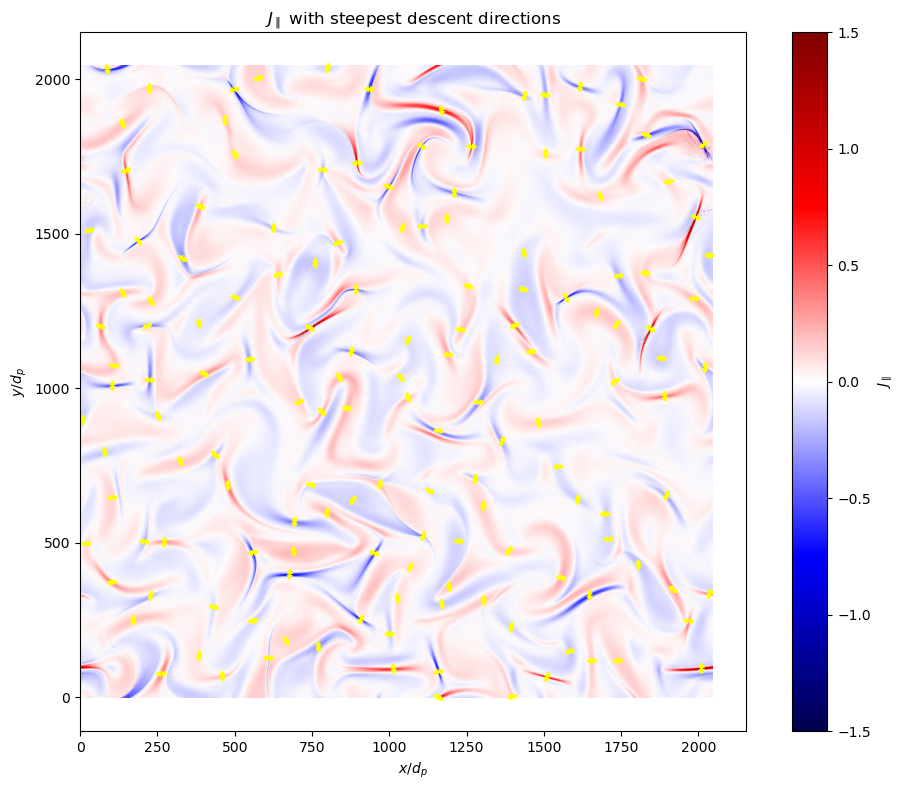

In [14]:
plot_eigenvectors_on_J(J_par_FT, directions, scale=5)

Detected current sheets: 3938


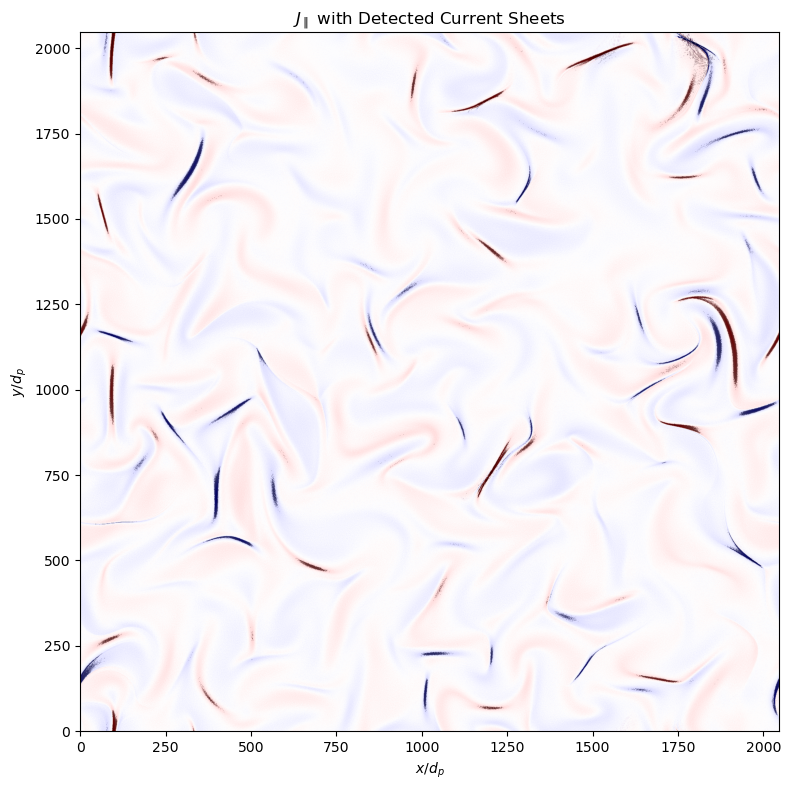

In [17]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label

# -------------------------------
# 1. LOAD DATA
# -------------------------------
File_Bx = '/DATA/DEVESH/ApJ2015/Bx_ApJ_t42.h5'
File_By = '/DATA/DEVESH/ApJ2015/By_ApJ_t42.h5'

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

# -------------------------------
# 2. COMPUTE J_parallel = dBy/dx - dBx/dy (FFT derivatives)
# -------------------------------
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

dx = dy = 0.125

J_par = partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dy)

# -------------------------------
# 3. CURRENT SHEET DETECTION (thresholding)
# -------------------------------

# Option: threshold at 99th percentile of |J|
threshold = np.quantile(np.abs(J_par), 0.99)

# Binary mask of current sheets
CS_mask = np.abs(J_par) > threshold

# Label connected structures
labels, num_cs = label(CS_mask)
print("Detected current sheets:", num_cs)

# -------------------------------
# 4. PLOT: J_parallel + CS overlay
# -------------------------------
plt.figure(figsize=(10, 8))

plt.imshow(J_par.T, cmap='seismic', vmin=-1.5, vmax=1.5,
           origin='lower')

# Overlay detected CS in semi-transparent black/gray
plt.imshow(~CS_mask.T, cmap='gray',alpha=0.6, origin='lower')

plt.title(r'$J_\parallel$ with Detected Current Sheets')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_current_sheets.png", dpi=300)
plt.show()

0.1330357641857075
1.830590684695791
Binary mask stats: (array([0, 1]), array([4083801,  110503]))


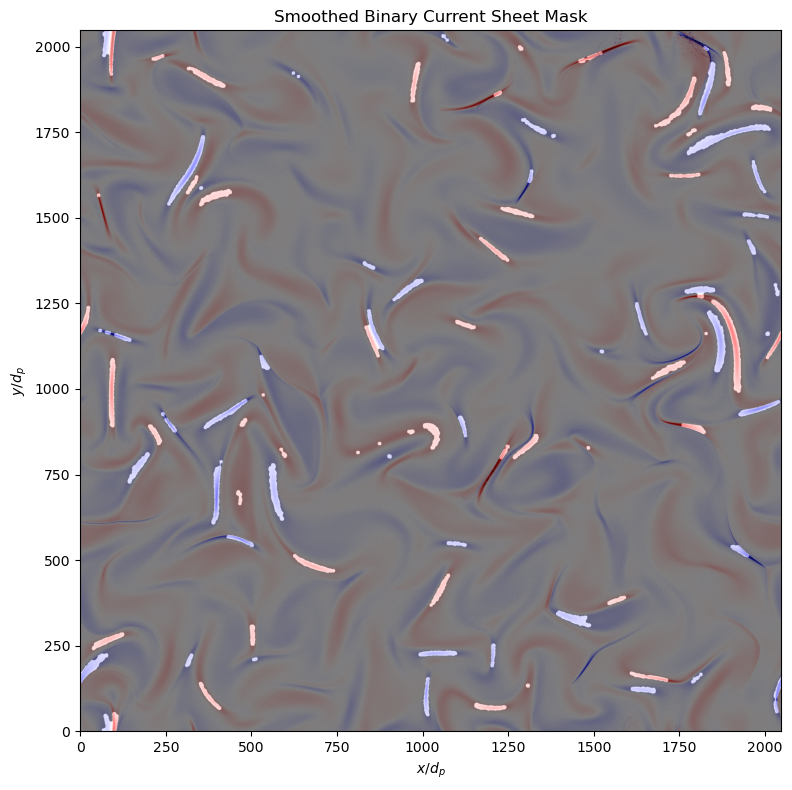

In [26]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology

# -------------------------------
# 1. LOAD DATA
# -------------------------------
File_Bx = '/DATA/DEVESH/ApJ2015/Bx_ApJ_t42.h5'
File_By = '/DATA/DEVESH/ApJ2015/By_ApJ_t42.h5'

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T

# -------------------------------
# 2. COMPUTE J_parallel = dBy/dx - dBx/dy (FFT derivatives)
# -------------------------------
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

dx = dy = 0.125
J_par = partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dy)

# -------------------------------
# 3. THRESHOLDING
# -------------------------------
threshold = np.quantile(np.abs(J_par), 0.9)
print(threshold)
threshold1 = 0.5*np.max(np.abs(J_par))
print(threshold1)
binary_mask = np.abs(J_par) > threshold   # boolean mask

# -------------------------------
# 4. MORPHOLOGICAL SMOOTHING
# -------------------------------
# Disk radius = 5 pixels (adjust depending on grid resolution)
struct = morphology.disk(5)

# Opening removes noise and small blobs
smoothed_mask = morphology.binary_opening(binary_mask, struct)

# Closing fills small holes inside detected sheets
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)

# Convert to 0/1 binary mask
smoothed_mask = smoothed_mask.astype(int)

print("Binary mask stats:", np.unique(smoothed_mask, return_counts=True))

# -------------------------------
# 5. PLOT
# -------------------------------
plt.figure(figsize=(10, 8))

plt.imshow(J_par.T, cmap='seismic', vmin=-1.5, vmax=1.5, origin='lower')
plt.imshow(smoothed_mask.T, cmap='gray', alpha=0.5, origin='lower')

plt.title(r'Smoothed Binary Current Sheet Mask')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_current_sheets_morphology.png", dpi=300)
plt.show()


In [3]:
import numpy as np
from skimage import measure

def remove_small_regions(mask, min_area):
    """
    Remove connected components in a binary mask that
    have area smaller than min_area (in pixels).
    
    mask: 2D numpy array of dtype bool or int (0/1)
    min_area: minimum allowed area for a connected region
    """
    mask_bool = mask.astype(bool)

    # Label connected components
    labels = measure.label(mask_bool, connectivity=2)

    # Properties of labeled regions
    props = measure.regionprops(labels)

    # Start with an empty mask
    filtered = np.zeros_like(mask_bool)

    # Keep only components with area ≥ min_area
    for p in props:
        if p.area >= min_area:
            filtered[labels == p.label] = True

    return filtered.astype(int)

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology

# ---------------------------------------------------------
# 0. FOURIER ZERO-PADDING 2D INTERPOLATION
# ---------------------------------------------------------
def fourier_interpolate_2d(arr, pad_factor=4):
    """Upsample a 2D field using Fourier zero-padding (band-limited interpolation)."""
    Nx, Ny = arr.shape

    # FFT of input field
    A = np.fft.fft2(arr)

    # Target larger grid
    Nx_big = pad_factor * Nx
    Ny_big = pad_factor * Ny

    # Create padded Fourier array
    A_big = np.zeros((Nx_big, Ny_big), dtype=complex)

    # Indices for inserting the Fourier coefficients in the center
    # NOTE: fftfreq ordering → low freq in middle after fftshift
    A_shift = np.fft.fftshift(A)

    x0 = Nx_big//2 - Nx//2
    y0 = Ny_big//2 - Ny//2

    # Copy original spectrum into center of big array
    A_big[x0:x0+Nx, y0:y0+Ny] = A_shift

    # Shift back
    A_big = np.fft.ifftshift(A_big)

    # Inverse FFT → high-res interpolated field
    a_big = np.fft.ifft2(A_big)

    return np.real(a_big)


# ---------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------
File_Bx = '/DATA/DEVESH/ApJ2015/Bx_ApJ_t42.h5'
File_By = '/DATA/DEVESH/ApJ2015/By_ApJ_t42.h5'

with h5py.File(File_Bx, 'r') as fBx, h5py.File(File_By, 'r') as fBy:
    data_Bx = fBx['DS1'][:].T
    data_By = fBy['DS1'][:].T


# ---------------------------------------------------------
# 2. COMPUTE J_parallel = dBy/dx - dBx/dy (FFT derivatives)
# ---------------------------------------------------------
def partial_x_fft(f, dx):
    nx, ny = f.shape
    kx = 2 * np.pi * np.fft.fftfreq(nx, d=dx)
    f_fft = np.fft.fft(f, axis=0)
    df_fft = 1j * kx[:, None] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=0))

def partial_y_fft(f, dy):
    nx, ny = f.shape
    ky = 2 * np.pi * np.fft.fftfreq(ny, d=dy)
    f_fft = np.fft.fft(f, axis=1)
    df_fft = 1j * ky[None, :] * f_fft
    return np.real(np.fft.ifft(df_fft, axis=1))

dx = dy = 0.125
J_par = partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dy)


# ---------------------------------------------------------
# 3. FOURIER INTERPOLATE J_parallel TO HIGHER RESOLUTION
# ---------------------------------------------------------
pad_factor = 4   # 4× finer grid
J_par_hr = fourier_interpolate_2d(J_par, pad_factor=pad_factor)

print("Original shape:", J_par.shape)
print("Upsampled shape:", J_par_hr.shape)


# ---------------------------------------------------------
# 4. THRESHOLDING ON HIGHER-RESOLUTION FIELD
# ---------------------------------------------------------
threshold = np.quantile(np.abs(J_par_hr), 0.9)
binary_mask = np.abs(J_par_hr) > threshold


# ---------------------------------------------------------
# 5. MORPHOLOGICAL SMOOTHING
# ---------------------------------------------------------
struct = morphology.disk(5)

smoothed_mask = morphology.binary_opening(binary_mask, struct)
smoothed_mask = morphology.binary_closing(smoothed_mask, struct)
smoothed_mask = smoothed_mask.astype(int)

print("Binary mask stats:", np.unique(smoothed_mask, return_counts=True))

Original shape: (2048, 2048)
Upsampled shape: (8192, 8192)
Binary mask stats: (array([0, 1]), array([64116664,  2992200]))


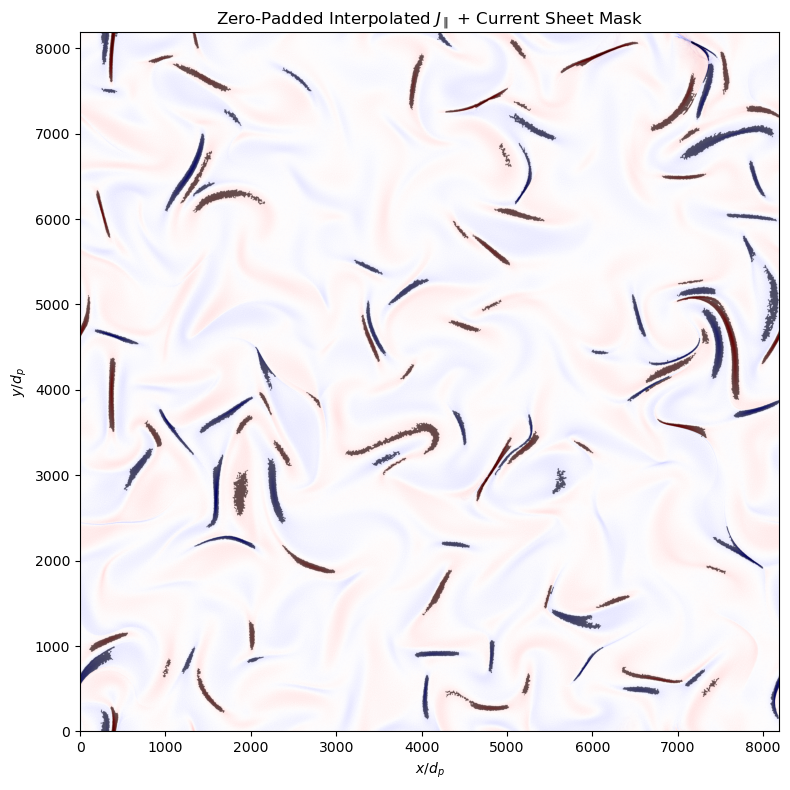

In [4]:
min_area = 5000   # choose based on physical sheet size
cleaned_mask = remove_small_regions(smoothed_mask, min_area)

# ---------------------------------------------------------
# 6. PLOTTING
# ---------------------------------------------------------
plt.figure(figsize=(10, 8))
plt.imshow((J_par_hr*(pad_factor**2)).T, cmap='seismic', origin='lower', vmin=-1.5, vmax=1.5)
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

plt.title(r'Zero-Padded Interpolated $J_\parallel$ + Current Sheet Mask')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_current_sheets_interpolated.png", dpi=300)
plt.show()

In [20]:
import numpy as np
from scipy import ndimage as ndi
from skimage import measure

# -----------------------------------------------------
# 1. Label the cleaned mask
# -----------------------------------------------------
labeled_mask = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask.max()
print("Number of connected regions:", num_regions)

# -----------------------------------------------------
# 2. Compute thicknesses
# -----------------------------------------------------
thicknesses = []

min_pixels = 10   # ignore tiny blobs

for label_id in range(1, num_regions + 1):

    region = (labeled_mask == label_id)

    # Skip small regions
    if np.sum(region) < min_pixels:
        continue

    # Euclidean distance transform INSIDE the region
    dist = ndi.distance_transform_edt(region)

    # Full sheet thickness = diameter of largest inscribed circle
    thickness = 2 * dist.max()

    thicknesses.append(thickness)

# -----------------------------------------------------
# 3. Report results
# -----------------------------------------------------
if len(thicknesses) > 0:
    print(f"Found {len(thicknesses)} sheets")
    print(f"Mean thickness = {np.mean(thicknesses):.3f} pixels")
    print(f"Median thickness = {np.median(thicknesses):.3f} pixels")
    print(f"Min thickness = {np.min(thicknesses):.3f} px, Max = {np.max(thicknesses):.3f} px")
else:
    print("No valid sheets found.")

Number of connected regions: 110
Found 110 sheets
Mean thickness = 59.831 pixels
Median thickness = 57.445 pixels
Min thickness = 26.306 px, Max = 120.017 px


In [ ]:
plt.figure(figsize=(14, 6))

# --- Original J_par ---
plt.subplot(1, 2, 1)
plt.imshow(J_par.T, cmap='seismic', origin='lower', vmin=-1.5, vmax=1.5)
plt.title("Original $J_\\parallel$")
plt.xlabel(r"$x/d_p$")
plt.ylabel(r"$y/d_p$")
plt.colorbar(label=r"$J_\parallel$")

# --- Interpolated J_par ---
plt.subplot(1, 2, 2)
J_par_hr *= (pad_factor**2)   # multiply by 16 for pad_factor=4
plt.imshow(J_par_hr.T, cmap='seismic', origin='lower', vmin=-1.5, vmax=1.5)
plt.title("Interpolated $J_\\parallel$ (Zero-Padded 4×)")
plt.xlabel(r"$x/d_p$")
plt.ylabel(r"$y/d_p$")
plt.colorbar(label=r"$J_\parallel$")

plt.tight_layout()
plt.show()

In [ ]:
# Number of connected regions: 110
# Found 110 sheets
# Mean thickness = 59.831 pixels
# Median thickness = 57.445 pixels
# Min thickness = 26.306 px, Max = 120.017 px

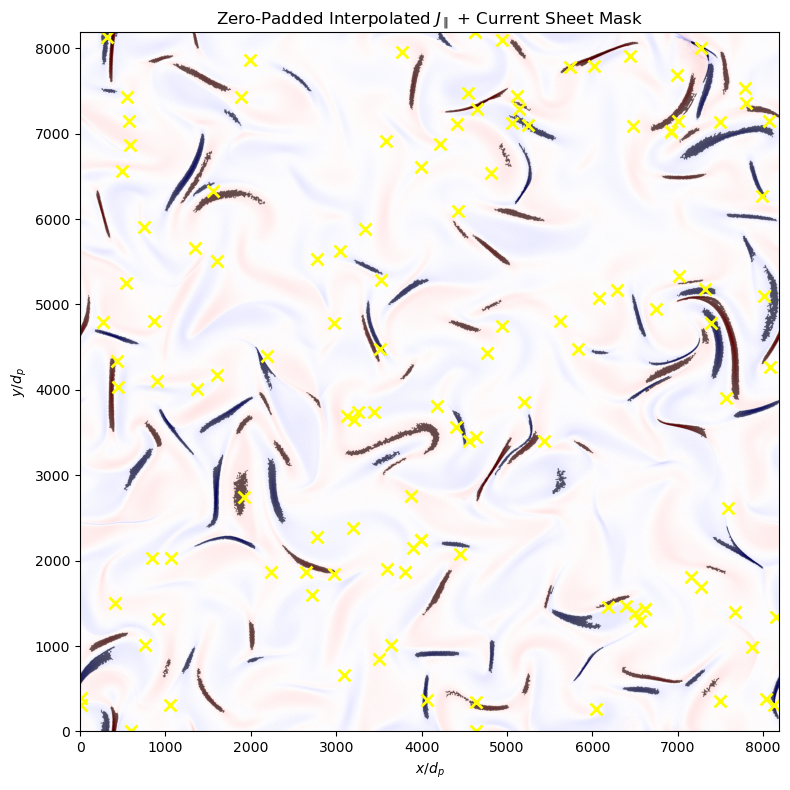

In [5]:
# --- FIND MAX LOCATIONS IN CLEANED MASK REGIONS ---
from scipy.ndimage import label

labeled, num = label(cleaned_mask)

max_coords = []
for i in range(1, num + 1):
    coords = np.where(labeled == i)
    vals = np.abs(J_par_hr)[coords]
    if len(vals) == 0:
        continue
    idx = np.argmax(vals)
    max_coords.append((coords[0][idx], coords[1][idx]))   # (x, y)


# --- PLOT WITH YELLOW CROSSES ---
plt.figure(figsize=(10, 8))
plt.imshow((J_par_hr*(pad_factor**2)).T, cmap='seismic', origin='lower', 
           vmin=-1.5, vmax=1.5)
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

# plot crosses
for x, y in max_coords:
    plt.plot(y, x, 'x', color='yellow', markersize=8, markeredgewidth=2)

plt.title(r'Zero-Padded Interpolated $J_\parallel$ + Current Sheet Mask')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig("Jpar_current_sheets_interpolated.png", dpi=300)
plt.show()

In [10]:
from scipy.ndimage import label

labeled, num = label(cleaned_mask)

max_coords = []
for i in range(1, num + 1):
    region = (labeled == i)
    vals = np.abs(J_par_hr)[region]
    if vals.size == 0:
        continue
    idx = np.argmax(vals)

    # Convert flat index → 2D coords
    coords = np.where(region)
    max_coords.append((coords[0][idx], coords[1][idx]))   # (x, y)

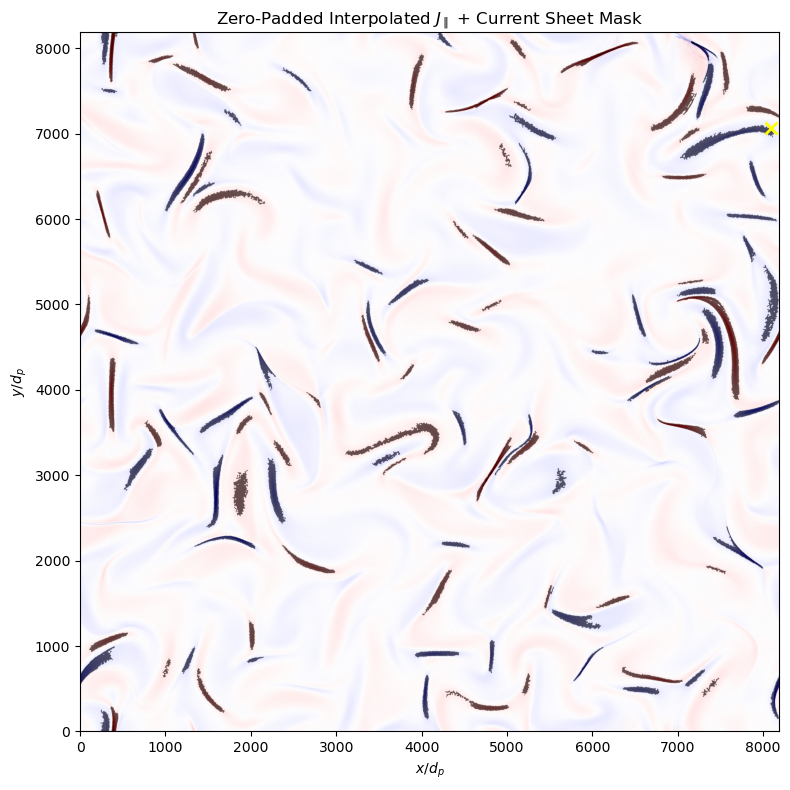

In [11]:
plt.figure(figsize=(10, 8))
plt.imshow((J_par_hr*(pad_factor**2)).T, cmap='seismic', origin='lower',
           vmin=-1.5, vmax=1.5)
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.6, origin='lower')

# plot region maxima
for x, y in max_coords:
    plt.plot(y, x, 'x', color='yellow', markersize=8, markeredgewidth=2)

plt.title(r'Zero-Padded Interpolated $J_\parallel$ + Current Sheet Mask')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')

plt.tight_layout()
# plt.savefig("Jpar_current_sheets_interpolated.png", dpi=300)
plt.show()

Number of connected regions found: 123

=== REGION WITH MAXIMUM J_par_hr VALUE ===
Region label: 107
Maximum J_par_hr value: -0.258436
Region size: 11422 pixels

=== J_par_hr STATISTICS ACROSS ALL REGIONS ===
Number of regions: 123
Global maximum |J_par_hr| in regions: 0.258436
Mean of region maxima: 0.037586
Std of region maxima: 0.035176

=== TOP 10 REGIONS BY |J_par_hr| VALUE ===
Rank 1: Region 107
  Extreme J_par_hr: -0.258436
  Size: 11422 pixels
  Mean: -0.048449, Std: 0.035582

Rank 2: Region 70
  Extreme J_par_hr: 0.208922
  Size: 31793 pixels
  Mean: 0.036444, Std: 0.029079

Rank 3: Region 63
  Extreme J_par_hr: 0.162311
  Size: 23798 pixels
  Mean: 0.030966, Std: 0.022092

Rank 4: Region 85
  Extreme J_par_hr: 0.131314
  Size: 36270 pixels
  Mean: 0.035968, Std: 0.026512

Rank 5: Region 79
  Extreme J_par_hr: -0.115273
  Size: 23183 pixels
  Mean: -0.021837, Std: 0.016202

Rank 6: Region 113
  Extreme J_par_hr: -0.102797
  Size: 32352 pixels
  Mean: -0.021555, Std: 0.013540



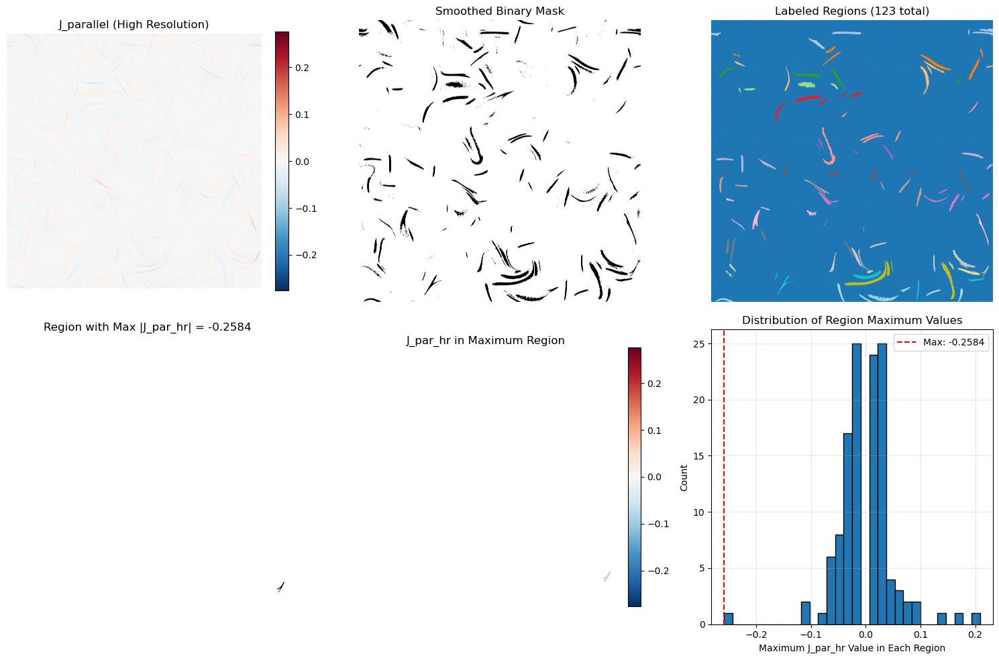

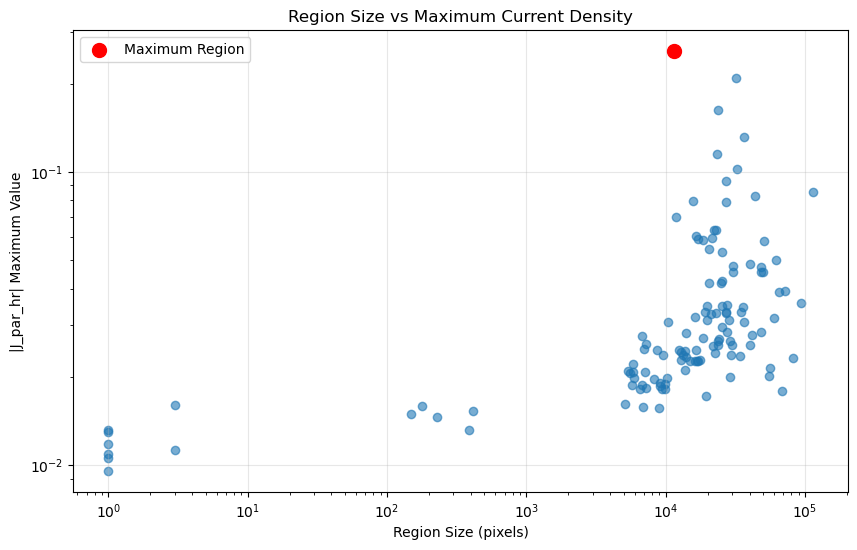

In [9]:
# ---------------------------------------------------------
# 6. FIND MAXIMUM J_par_hr VALUES IN EACH CONNECTED REGION
# ---------------------------------------------------------

# Label connected components in the smoothed mask
labeled_mask, num_features = label(cleaned_mask)

print(f"Number of connected regions found: {num_features}")

# Find the maximum J_par_hr value in each connected region
region_max_values = []
region_info = []

for i in range(1, num_features + 1):  # Labels start from 1
    # Create mask for current region
    region_mask = (labeled_mask == i)
    
    # Extract J_par_hr values in this region
    region_values = J_par_hr[region_mask]
    
    # Find maximum absolute value and actual maximum value
    max_abs_value = np.max(np.abs(region_values))
    max_value = np.max(region_values)
    min_value = np.min(region_values)
    
    # Determine which has larger absolute value
    if abs(min_value) > abs(max_value):
        extreme_value = min_value
    else:
        extreme_value = max_value
    
    region_max_values.append(extreme_value)
    
    # Store additional info
    region_info.append({
        'label': i,
        'size': np.sum(region_mask),
        'max_value': max_value,
        'min_value': min_value,
        'max_abs_value': max_abs_value,
        'extreme_value': extreme_value,
        'mean_value': np.mean(region_values),
        'std_value': np.std(region_values)
    })

# Convert to numpy array for easier manipulation
region_max_values = np.array(region_max_values)

if len(region_max_values) > 0:
    # Find the region with the maximum J_par_hr value
    max_idx = np.argmax(np.abs(region_max_values))
    max_region_label = max_idx + 1  # +1 because labels start from 1
    max_region_value = region_max_values[max_idx]
    
    print(f"\n=== REGION WITH MAXIMUM J_par_hr VALUE ===")
    print(f"Region label: {max_region_label}")
    print(f"Maximum J_par_hr value: {max_region_value:.6f}")
    print(f"Region size: {region_info[max_idx]['size']} pixels")
    
    # Overall statistics
    print(f"\n=== J_par_hr STATISTICS ACROSS ALL REGIONS ===")
    print(f"Number of regions: {num_features}")
    print(f"Global maximum |J_par_hr| in regions: {np.max(np.abs(region_max_values)):.6f}")
    print(f"Mean of region maxima: {np.mean(np.abs(region_max_values)):.6f}")
    print(f"Std of region maxima: {np.std(np.abs(region_max_values)):.6f}")
    
    # Top 10 regions by J_par_hr value
    print(f"\n=== TOP 10 REGIONS BY |J_par_hr| VALUE ===")
    sorted_indices = np.argsort(np.abs(region_max_values))[::-1][:10]
    for rank, idx in enumerate(sorted_indices, 1):
        info = region_info[idx]
        print(f"Rank {rank}: Region {info['label']}")
        print(f"  Extreme J_par_hr: {info['extreme_value']:.6f}")
        print(f"  Size: {info['size']} pixels")
        print(f"  Mean: {info['mean_value']:.6f}, Std: {info['std_value']:.6f}")
        print()
    
    # Create visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Original J_par_hr field
    im1 = axes[0, 0].imshow(J_par_hr, cmap='RdBu_r', vmin=-np.max(np.abs(J_par_hr)), vmax=np.max(np.abs(J_par_hr)))
    axes[0, 0].set_title('J_parallel (High Resolution)')
    axes[0, 0].axis('off')
    plt.colorbar(im1, ax=axes[0, 0], fraction=0.046)
    
    # Smoothed binary mask
    axes[0, 1].imshow(smoothed_mask, cmap='binary')
    axes[0, 1].set_title('Smoothed Binary Mask')
    axes[0, 1].axis('off')
    
    # Labeled regions
    im3 = axes[0, 2].imshow(labeled_mask, cmap='tab20')
    axes[0, 2].set_title(f'Labeled Regions ({num_features} total)')
    axes[0, 2].axis('off')
    
    # Highlight region with maximum J_par_hr
    max_region_mask = (labeled_mask == max_region_label)
    axes[1, 0].imshow(max_region_mask, cmap='binary')
    axes[1, 0].set_title(f'Region with Max |J_par_hr| = {max_region_value:.4f}')
    axes[1, 0].axis('off')
    
    # Show J_par_hr values only in the maximum region
    masked_J_par = np.ma.masked_where(~max_region_mask, J_par_hr)
    im5 = axes[1, 1].imshow(masked_J_par, cmap='RdBu_r', vmin=-np.max(np.abs(J_par_hr)), vmax=np.max(np.abs(J_par_hr)))
    axes[1, 1].set_title('J_par_hr in Maximum Region')
    axes[1, 1].axis('off')
    plt.colorbar(im5, ax=axes[1, 1], fraction=0.046)
    
    # Histogram of maximum values across regions
    axes[1, 2].hist(region_max_values, bins=30, edgecolor='black')
    axes[1, 2].axvline(max_region_value, color='red', linestyle='--', label=f'Max: {max_region_value:.4f}')
    axes[1, 2].set_xlabel('Maximum J_par_hr Value in Each Region')
    axes[1, 2].set_ylabel('Count')
    axes[1, 2].set_title('Distribution of Region Maximum Values')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Additional plot: Scatter plot of region size vs maximum J_par_hr
    plt.figure(figsize=(10, 6))
    sizes = [info['size'] for info in region_info]
    max_vals = [abs(info['extreme_value']) for info in region_info]
    
    plt.scatter(sizes, max_vals, alpha=0.6)
    plt.scatter(region_info[max_idx]['size'], abs(region_info[max_idx]['extreme_value']), 
                color='red', s=100, label='Maximum Region', zorder=5)
    
    plt.xlabel('Region Size (pixels)')
    plt.ylabel('|J_par_hr| Maximum Value')
    plt.title('Region Size vs Maximum Current Density')
    plt.xscale('log')
    plt.yscale('log')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
    
else:
    print("No connected regions found in the mask!")

Number of connected regions found: 123

=== REGION WITH MAXIMUM J_par_hr VALUE ===
Region label: 107
Maximum J_par_hr value: -0.258436
Region size: 11422 pixels

=== J_par_hr STATISTICS ACROSS ALL REGIONS ===
Number of regions: 123
Global maximum |J_par_hr| in regions: 0.258436
Mean of region maxima: 0.037586
Std of region maxima: 0.035176

=== TOP 10 REGIONS BY |J_par_hr| VALUE ===
Rank 1: Region 107
  Extreme J_par_hr: -0.258436
  Size: 11422 pixels
  Mean: -0.048449, Std: 0.035582

Rank 2: Region 70
  Extreme J_par_hr: 0.208922
  Size: 31793 pixels
  Mean: 0.036444, Std: 0.029079

Rank 3: Region 63
  Extreme J_par_hr: 0.162311
  Size: 23798 pixels
  Mean: 0.030966, Std: 0.022092

Rank 4: Region 85
  Extreme J_par_hr: 0.131314
  Size: 36270 pixels
  Mean: 0.035968, Std: 0.026512

Rank 5: Region 79
  Extreme J_par_hr: -0.115273
  Size: 23183 pixels
  Mean: -0.021837, Std: 0.016202

Rank 6: Region 113
  Extreme J_par_hr: -0.102797
  Size: 32352 pixels
  Mean: -0.021555, Std: 0.013540



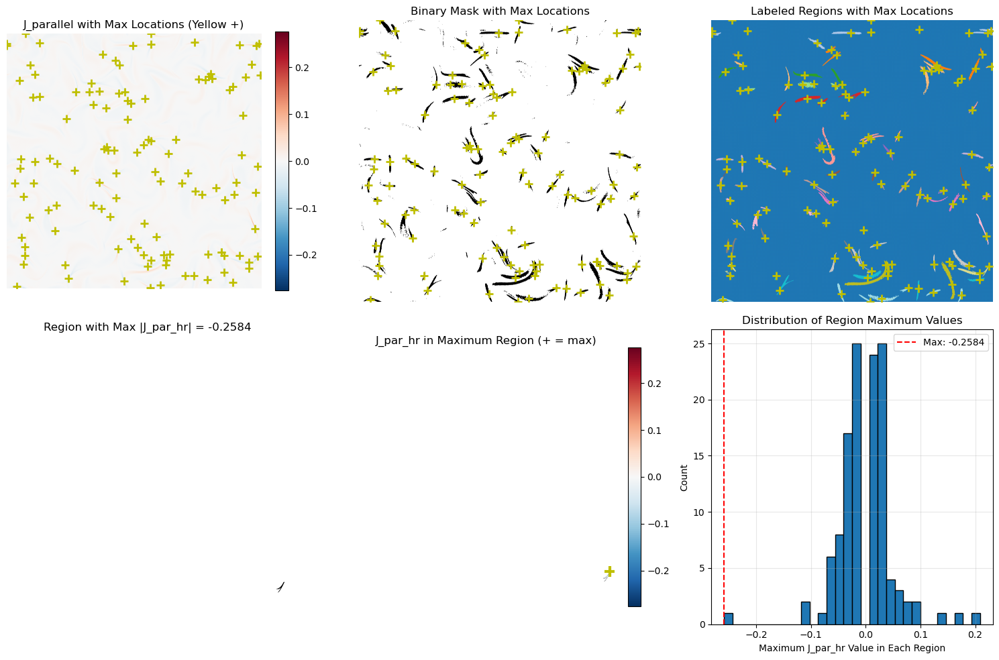

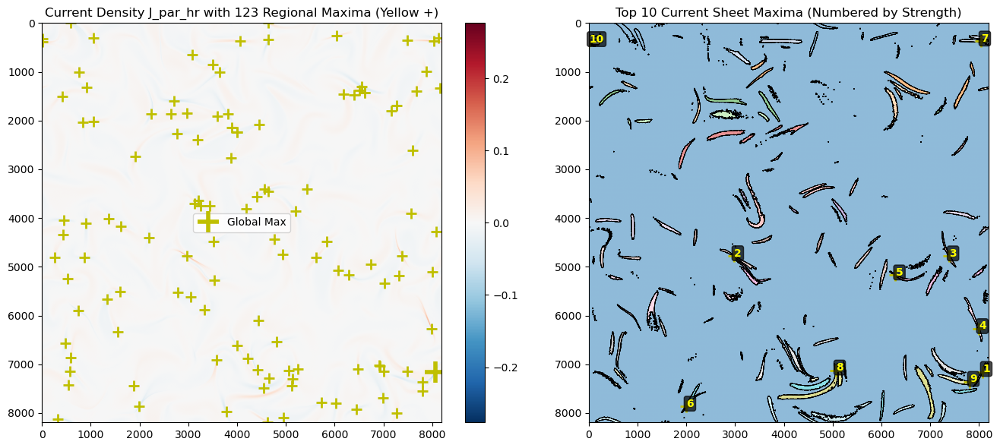

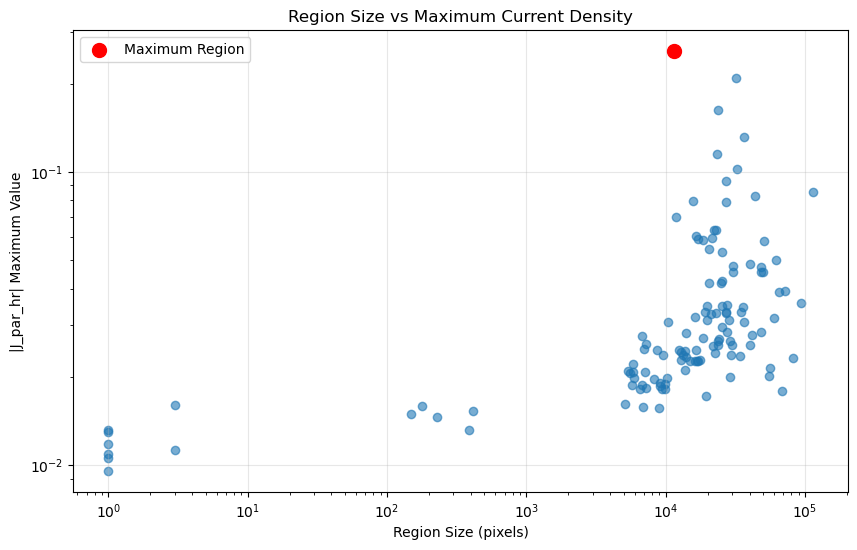

In [13]:
# ---------------------------------------------------------
# 6. FIND MAXIMUM J_par_hr VALUES IN EACH CONNECTED REGION
# ---------------------------------------------------------

# Label connected components in the smoothed mask
labeled_mask, num_features = label(cleaned_mask)

print(f"Number of connected regions found: {num_features}")

# Find the maximum J_par_hr value in each connected region
region_max_values = []
region_info = []
max_coordinates = []  # Store coordinates of maximum values

for i in range(1, num_features + 1):  # Labels start from 1
    # Create mask for current region
    region_mask = (labeled_mask == i)
    
    # Extract J_par_hr values in this region
    region_values = J_par_hr[region_mask]
    
    # Find maximum absolute value and actual maximum value
    max_abs_value = np.max(np.abs(region_values))
    max_value = np.max(region_values)
    min_value = np.min(region_values)
    
    # Determine which has larger absolute value
    if abs(min_value) > abs(max_value):
        extreme_value = min_value
        # Find coordinates of minimum (since it has larger absolute value)
        region_J_par = np.where(region_mask, J_par_hr, np.inf)
        max_coord = np.unravel_index(np.argmin(region_J_par), J_par_hr.shape)
    else:
        extreme_value = max_value
        # Find coordinates of maximum
        region_J_par = np.where(region_mask, J_par_hr, -np.inf)
        max_coord = np.unravel_index(np.argmax(region_J_par), J_par_hr.shape)
    
    region_max_values.append(extreme_value)
    max_coordinates.append(max_coord)
    
    # Store additional info
    region_info.append({
        'label': i,
        'size': np.sum(region_mask),
        'max_value': max_value,
        'min_value': min_value,
        'max_abs_value': max_abs_value,
        'extreme_value': extreme_value,
        'mean_value': np.mean(region_values),
        'std_value': np.std(region_values),
        'max_coord': max_coord
    })

# Convert to numpy array for easier manipulation
region_max_values = np.array(region_max_values)

if len(region_max_values) > 0:
    # Find the region with the maximum J_par_hr value
    max_idx = np.argmax(np.abs(region_max_values))
    max_region_label = max_idx + 1  # +1 because labels start from 1
    max_region_value = region_max_values[max_idx]
    
    print(f"\n=== REGION WITH MAXIMUM J_par_hr VALUE ===")
    print(f"Region label: {max_region_label}")
    print(f"Maximum J_par_hr value: {max_region_value:.6f}")
    print(f"Region size: {region_info[max_idx]['size']} pixels")
    
    # Overall statistics
    print(f"\n=== J_par_hr STATISTICS ACROSS ALL REGIONS ===")
    print(f"Number of regions: {num_features}")
    print(f"Global maximum |J_par_hr| in regions: {np.max(np.abs(region_max_values)):.6f}")
    print(f"Mean of region maxima: {np.mean(np.abs(region_max_values)):.6f}")
    print(f"Std of region maxima: {np.std(np.abs(region_max_values)):.6f}")
    
    # Top 10 regions by J_par_hr value
    print(f"\n=== TOP 10 REGIONS BY |J_par_hr| VALUE ===")
    sorted_indices = np.argsort(np.abs(region_max_values))[::-1][:10]
    for rank, idx in enumerate(sorted_indices, 1):
        info = region_info[idx]
        print(f"Rank {rank}: Region {info['label']}")
        print(f"  Extreme J_par_hr: {info['extreme_value']:.6f}")
        print(f"  Size: {info['size']} pixels")
        print(f"  Mean: {info['mean_value']:.6f}, Std: {info['std_value']:.6f}")
        print()
    
    # Create visualization
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Original J_par_hr field with yellow crosses at maxima
    im1 = axes[0, 0].imshow(J_par_hr, cmap='RdBu_r', vmin=-np.max(np.abs(J_par_hr)), vmax=np.max(np.abs(J_par_hr)))
    # Plot yellow crosses for each region's maximum
    for coord in max_coordinates:
        axes[0, 0].plot(coord[1], coord[0], 'y+', markersize=8, markeredgewidth=2)
    axes[0, 0].set_title('J_parallel with Max Locations (Yellow +)')
    axes[0, 0].axis('off')
    plt.colorbar(im1, ax=axes[0, 0], fraction=0.046)
    
    # Smoothed binary mask with yellow crosses
    axes[0, 1].imshow(smoothed_mask, cmap='binary')
    for coord in max_coordinates:
        axes[0, 1].plot(coord[1], coord[0], 'y+', markersize=8, markeredgewidth=2)
    axes[0, 1].set_title('Binary Mask with Max Locations')
    axes[0, 1].axis('off')
    
    # Labeled regions with yellow crosses
    im3 = axes[0, 2].imshow(labeled_mask, cmap='tab20')
    for coord in max_coordinates:
        axes[0, 2].plot(coord[1], coord[0], 'y+', markersize=8, markeredgewidth=2)
    axes[0, 2].set_title(f'Labeled Regions with Max Locations')
    axes[0, 2].axis('off')
    
    # Highlight region with maximum J_par_hr
    max_region_mask = (labeled_mask == max_region_label)
    axes[1, 0].imshow(max_region_mask, cmap='binary')
    axes[1, 0].set_title(f'Region with Max |J_par_hr| = {max_region_value:.4f}')
    axes[1, 0].axis('off')
    
    # Show J_par_hr values only in the maximum region
    masked_J_par = np.ma.masked_where(~max_region_mask, J_par_hr)
    im5 = axes[1, 1].imshow(masked_J_par, cmap='RdBu_r', vmin=-np.max(np.abs(J_par_hr)), vmax=np.max(np.abs(J_par_hr)))
    # Highlight the maximum point in this region
    axes[1, 1].plot(max_coordinates[max_idx][1], max_coordinates[max_idx][0], 'y+', 
                    markersize=12, markeredgewidth=3)
    axes[1, 1].set_title('J_par_hr in Maximum Region (+ = max)')
    axes[1, 1].axis('off')
    plt.colorbar(im5, ax=axes[1, 1], fraction=0.046)
    
    # Histogram of maximum values across regions
    axes[1, 2].hist(region_max_values, bins=30, edgecolor='black')
    axes[1, 2].axvline(max_region_value, color='red', linestyle='--', label=f'Max: {max_region_value:.4f}')
    axes[1, 2].set_xlabel('Maximum J_par_hr Value in Each Region')
    axes[1, 2].set_ylabel('Count')
    axes[1, 2].set_title('Distribution of Region Maximum Values')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Create a dedicated figure showing all maximum locations
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Left plot: J_par_hr field with all maxima marked
    im = axes[0].imshow(J_par_hr, cmap='RdBu_r', vmin=-np.max(np.abs(J_par_hr)), vmax=np.max(np.abs(J_par_hr)))
    
    # Plot yellow crosses for ALL maxima
    for i, (coord, value) in enumerate(zip(max_coordinates, region_max_values)):
        axes[0].plot(coord[1], coord[0], 'y+', markersize=10, markeredgewidth=2)
    
    # Highlight the global maximum with a larger marker
    axes[0].plot(max_coordinates[max_idx][1], max_coordinates[max_idx][0], 'y+', 
                 markersize=20, markeredgewidth=4, label='Global Max')
    
    axes[0].set_title(f'Current Density J_par_hr with {num_features} Regional Maxima (Yellow +)')
    axes[0].legend()
    plt.colorbar(im, ax=axes[0], fraction=0.046)
    
    # Right plot: Zoomed view of regions with maxima numbered
    axes[1].imshow(labeled_mask, cmap='tab20', alpha=0.5)
    axes[1].contour(smoothed_mask, colors='black', linewidths=0.5)
    
    # Plot and number the top 10 maxima
    sorted_indices = np.argsort(np.abs(region_max_values))[::-1][:min(10, len(region_max_values))]
    for rank, idx in enumerate(sorted_indices, 1):
        coord = max_coordinates[idx]
        axes[1].plot(coord[1], coord[0], 'y+', markersize=12, markeredgewidth=2)
        axes[1].text(coord[1]+5, coord[0]+5, f'{rank}', color='yellow', fontsize=10, 
                    fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.7))
    
    axes[1].set_title('Top 10 Current Sheet Maxima (Numbered by Strength)')
    
    plt.tight_layout()
    plt.show()
    
    # Additional plot: Scatter plot of region size vs maximum J_par_hr
    plt.figure(figsize=(10, 6))
    sizes = [info['size'] for info in region_info]
    max_vals = [abs(info['extreme_value']) for info in region_info]
    
    plt.scatter(sizes, max_vals, alpha=0.6)
    plt.scatter(region_info[max_idx]['size'], abs(region_info[max_idx]['extreme_value']), 
                color='red', s=100, label='Maximum Region', zorder=5)
    
    plt.xlabel('Region Size (pixels)')
    plt.ylabel('|J_par_hr| Maximum Value')
    plt.title('Region Size vs Maximum Current Density')
    plt.xscale('log')
    plt.yscale('log')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()
    
else:
    print("No connected regions found in the mask!")

In [15]:
np.max(np.abs(J_par_hr))

np.float64(0.2763859509202456)

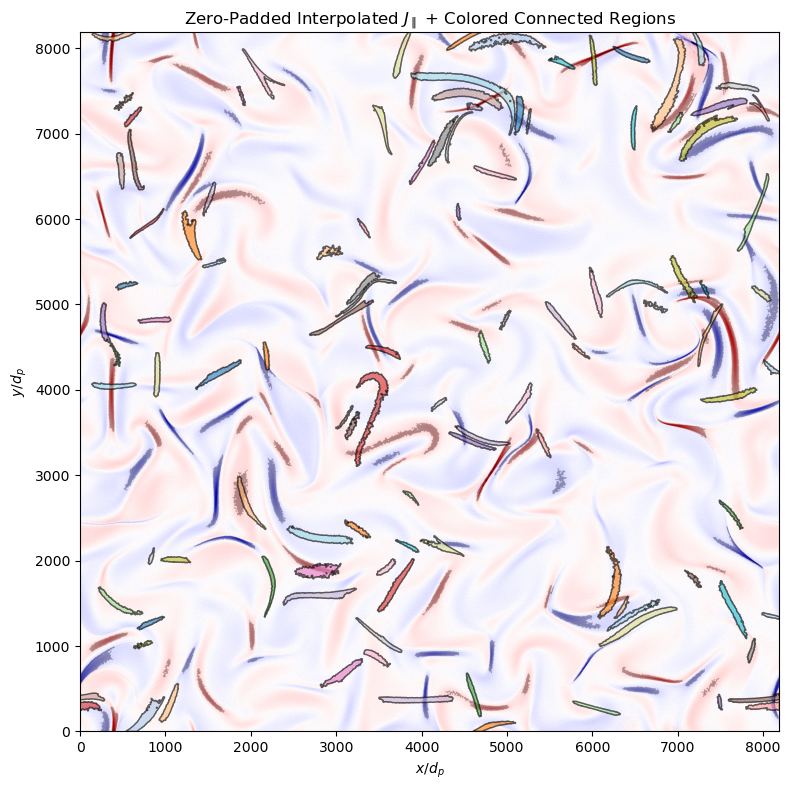

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage.measure import find_contours
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

# --- Label connected regions ---
labeled_mask, num = label(cleaned_mask)

plt.figure(figsize=(10, 8))

# Base J_parallel image
plt.imshow((J_par_hr*(pad_factor**2)).T, cmap='seismic', origin='lower',
           vmin=-1.5, vmax=1.5)

# Semi-transparent full mask overlay
plt.imshow(~cleaned_mask.T, cmap='gray', alpha=0.3, origin='lower')

patches = []
colors = []

cmap = plt.get_cmap('tab20')

# --- Extract each region as a polygon and color it ---
for region_id in range(1, num + 1):
    region_mask = (labeled_mask == region_id).T

    # find region boundary
    contours = find_contours(region_mask.astype(float), 0.5)

    for contour in contours:
        # Build a polygon for filling
        poly = Polygon(contour, closed=True)
        patches.append(poly)
        colors.append(cmap(region_id % 20))

# Add filled colored patches with black edges
p = PatchCollection(
    patches,
    facecolor=colors,
    edgecolor='black',
    linewidth=1.0,
    alpha=0.6
)
plt.gca().add_collection(p)

plt.title(r'Zero-Padded Interpolated $J_\parallel$ + Colored Connected Regions')
plt.xlabel(r'$x/d_p$')
plt.ylabel(r'$y/d_p$')
plt.tight_layout()
plt.show()